# Statistical analysis of Online Retail II

The SQL part of the project (`sql/`) answers *what happened*: revenue, cohorts, RFM, ABC.
This notebook answers *how sure we can be* and *what model describes the data*:

1. Order value: lognormal model fitted by **MLE** and **method of moments**, checked with the **empirical CDF** and **Kolmogorov–Smirnov**.
2. **Confidence intervals** for the mean and median order value: CLT vs bootstrap (Monte Carlo).
3. **Hypothesis tests**: do UK and international orders differ in value? Do repeat-purchase rates differ?
4. Time between orders: **Gamma** model (MLE via `scipy.optimize`) vs exponential, likelihood-ratio test.
5. **Monte Carlo study** of the two Gamma shape estimators: bias, variance, MSE and consistency as *n* grows.

Cleaning rules are the same as in `sql/02_transform.sql`, so the numbers match the database.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import optimize, special, stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(42)

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.labelcolor": MUTED, "axes.titlecolor": INK, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.float_format", "{:,.4f}".format)

## 0. Load and clean

In [2]:
raw = pd.read_csv(ROOT / "data" / "raw" / "online_retail_ii.csv",
                  dtype={"invoice": str, "stock_code": str}, parse_dates=["invoice_date"])
df = raw.assign(stock_code=raw.stock_code.str.strip().str.upper(),
                country=raw.country.str.strip())
df = df[df.invoice.str.match(r"^C?\d+$") & (df.price > 0) & (df.quantity != 0)].drop_duplicates()
df = df.assign(revenue=df.quantity * df.price, is_cancellation=df.invoice.str.startswith("C"))

orders = (df[~df.is_cancellation]
          .groupby("invoice")
          .agg(value=("revenue", "sum"), customer_id=("customer_id", "first"),
               country=("country", "first"), ts=("invoice_date", "min")))
orders["uk"] = orders.country.eq("United Kingdom")

print(f"raw rows: {len(raw):,}  clean rows: {len(df):,}  (cancellation lines: {df.is_cancellation.sum():,})")
print(f"orders: {len(orders):,}  customers: {orders.customer_id.nunique():,}  "
      f"period: {df.invoice_date.min():%Y-%m-%d} .. {df.invoice_date.max():%Y-%m-%d}")
orders.value.describe(percentiles=[.05, .25, .5, .75, .95, .99]).to_frame("order value, £")

raw rows: 1,067,371  clean rows: 1,027,016  (cancellation lines: 19,104)
orders: 40,076  customers: 5,878  period: 2009-12-01 .. 2011-12-09


,"order value, £"
count,"40,076.0000"
mean,510.6597
std,"1,481.4103"
min,0.1900
5%,19.5000
25%,149.7500
50%,302.2200
75%,493.3925
95%,"1,512.3400"
99%,"4,401.8625"


Order value is strongly right-skewed: the mean is far above the median and the largest order is over 500× the median.
That already says a normal model is wrong and the mean is driven by a few wholesale orders.

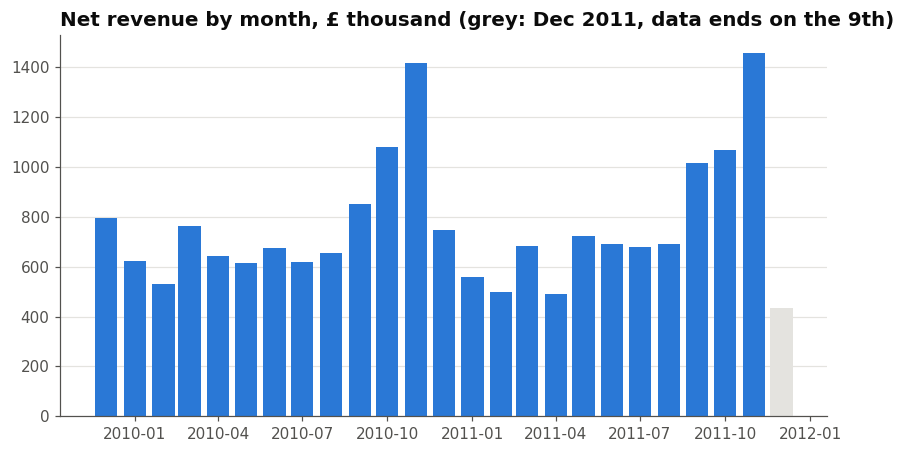

In [3]:
monthly = df.set_index("invoice_date").revenue.resample("MS").sum() / 1e3
fig, ax = plt.subplots()
colors = [BLUE] * (len(monthly) - 1) + [GRID]
ax.bar(monthly.index, monthly.values, width=24, color=colors)
ax.set_title("Net revenue by month, £ thousand (grey: Dec 2011, data ends on the 9th)")
ax.grid(axis="x", visible=False)
fig.savefig(FIG / "monthly_revenue.png")
plt.show()

## 1. Order value: lognormal model, MLE vs method of moments

If $X \sim \text{LogNormal}(\mu, \sigma^2)$:

* **MLE**: $\hat\mu = \overline{\ln x}$, $\hat\sigma^2 = \frac1n\sum(\ln x_i - \hat\mu)^2$.
* **Method of moments**: match $E X = e^{\mu+\sigma^2/2}$ and $\operatorname{Var} X = (e^{\sigma^2}-1)e^{2\mu+\sigma^2}$, so
  $\tilde\sigma^2 = \ln(1 + s^2/\bar x^2)$, $\tilde\mu = \ln\bar x - \tilde\sigma^2/2$.

In [4]:
x = orders.value.to_numpy()
logx = np.log(x)

mu_mle, sigma_mle = logx.mean(), logx.std(ddof=0)
m, v = x.mean(), x.var(ddof=0)
sigma_mom = np.sqrt(np.log1p(v / m**2))
mu_mom = np.log(m) - sigma_mom**2 / 2

fits = {"MLE": (mu_mle, sigma_mle), "Method of moments": (mu_mom, sigma_mom)}
rows = []
for name, (mu, s) in fits.items():
    dist = stats.lognorm(s=s, scale=np.exp(mu))
    ks = stats.kstest(x, dist.cdf)
    rows.append({"estimator": name, "mu": mu, "sigma": s,
                 "model median, £": dist.median(), "model mean, £": dist.mean(),
                 "KS D": ks.statistic, "log-likelihood": dist.logpdf(x).sum()})
lognorm_fit = pd.DataFrame(rows).set_index("estimator")
print(f"sample median £{np.median(x):,.2f}, sample mean £{m:,.2f}")
lognorm_fit

sample median £302.22, sample mean £510.66


,mu,sigma,"model median, £","model mean, £",KS D,log-likelihood
estimator,,,,,,
MLE,5.5291,1.2527,251.9189,552.1173,0.0898,"-287,479.6816"
Method of moments,5.1145,1.4974,166.4222,510.6597,0.2250,"-290,152.5423"


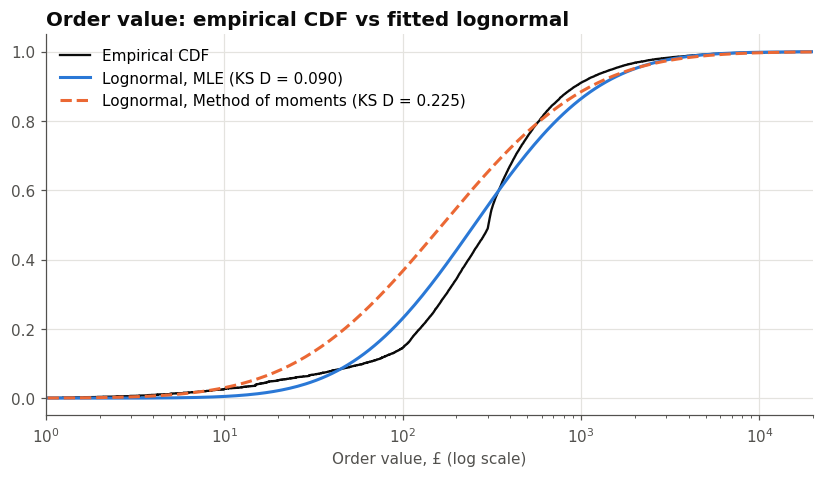

In [5]:
grid = np.logspace(np.log10(x.min()), np.log10(x.max()), 400)
xs = np.sort(x)
ecdf = np.arange(1, len(xs) + 1) / len(xs)

fig, ax = plt.subplots()
ax.step(xs, ecdf, where="post", color=INK, linewidth=1.5, label="Empirical CDF")
for (name, (mu, s)), c, ls in zip(fits.items(), [BLUE, ORANGE], ["-", "--"]):
    ax.plot(grid, stats.lognorm.cdf(grid, s=s, scale=np.exp(mu)), color=c, linestyle=ls,
            label=f"Lognormal, {name} (KS D = {lognorm_fit.loc[name, 'KS D']:.3f})")
ax.set_xscale("log")
ax.set_xlim(1, 2e4)
ax.set_xlabel("Order value, £ (log scale)")
ax.set_title("Order value: empirical CDF vs fitted lognormal")
ax.legend(loc="upper left")
fig.savefig(FIG / "order_value_ecdf.png")
plt.show()

**Reading.** MLE fits the body of the distribution far better: its KS distance is much smaller and its log-likelihood is higher.
The method of moments is pulled by the huge sample variance (a few orders of £10k+), so it overstates $\sigma$ and puts the model median far from the data.
With $n \approx 40\,000$ the KS test rejects *any* parametric model (p-value ≈ 0), and the parameters were estimated from the same data, which makes the standard KS p-value invalid anyway.
So I use $D$ as a distance, not as a pass/fail test. The lognormal model is a good working approximation for typical orders but underestimates the left tail (very small orders).

## 2. Confidence intervals for the mean and median order value

* **CLT**: $\bar x \pm z_{0.975}\, s/\sqrt n$. Valid for large $n$ even for skewed data, by the CLT and Slutsky (a consistent $s$ in place of $\sigma$).
* **Bootstrap** (Monte Carlo, $B = 2000$ resamples): percentile interval. The median has no simple CLT formula, so the bootstrap is the natural tool.

In [6]:
def bootstrap(data, stat, B=2000, chunk=100):
    out = []
    for _ in range(B // chunk):
        idx = rng.integers(0, len(data), size=(chunk, len(data)))
        out.append(stat(data[idx], axis=1))
    return np.concatenate(out)

z = stats.norm.ppf(0.975)
se = x.std(ddof=1) / np.sqrt(len(x))
boot_mean = bootstrap(x, np.mean)
boot_median = bootstrap(x, np.median)

ci = pd.DataFrame({
    "estimate, £": [x.mean(), x.mean(), np.median(x)],
    "low, £": [x.mean() - z * se, *np.percentile(boot_mean, [2.5]), *np.percentile(boot_median, [2.5])],
    "high, £": [x.mean() + z * se, *np.percentile(boot_mean, [97.5]), *np.percentile(boot_median, [97.5])],
}, index=["mean, CLT", "mean, bootstrap", "median, bootstrap"])
ci["width, £"] = ci["high, £"] - ci["low, £"]
ci

,"estimate, £","low, £","high, £","width, £"
"mean, CLT",510.6597,496.1559,525.1635,29.0076
"mean, bootstrap",510.6597,496.9082,526.4232,29.5150
"median, bootstrap",302.2200,301.0400,303.4500,2.4100


The CLT and bootstrap intervals for the mean almost coincide: with 40k orders the sampling distribution of $\bar x$ is already close to normal despite the skew.
The median interval is more than 10× narrower than the mean interval, so the median is the more stable KPI for a "typical order".

## 3. Hypothesis tests: UK vs international customers

**3a. Order value.** $H_0: \mu_{UK} = \mu_{Intl}$. Two large independent samples, so I use a two-sample **Z-test** with sample variances (Welch form).
Because the data are heavy-tailed, I also run **Mann–Whitney U** (are international orders *typically* larger?) and a Z-test on log values (ratio of geometric means).

In [7]:
uk, intl = x[orders.uk.to_numpy()], x[~orders.uk.to_numpy()]

def z_test(a, b):
    diff = a.mean() - b.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    zstat = diff / se
    return diff, (diff - z * se, diff + z * se), zstat, 2 * stats.norm.sf(abs(zstat))

diff, (lo, hi), zs, p = z_test(intl, uk)
dlog, (llo, lhi), zl, pl = z_test(np.log(intl), np.log(uk))
mw = stats.mannwhitneyu(intl, uk, alternative="two-sided")

print(f"orders: UK {len(uk):,}, international {len(intl):,}")
print(f"mean:   UK £{uk.mean():,.0f}, intl £{intl.mean():,.0f}")
print(f"median: UK £{np.median(uk):,.0f}, intl £{np.median(intl):,.0f}")
print(f"\nZ-test, difference of means (intl - UK): £{diff:,.0f}, 95% CI [£{lo:,.0f}; £{hi:,.0f}], z = {zs:.1f}, p = {p:.1e}")
print(f"Z-test on log values: geometric-mean ratio {np.exp(dlog):.2f}x, 95% CI [{np.exp(llo):.2f}x; {np.exp(lhi):.2f}x], p = {pl:.1e}")
print(f"Mann-Whitney U: p = {mw.pvalue:.1e}, P(intl order > UK order) = {mw.statistic / (len(uk) * len(intl)):.3f}")

orders: UK 36,534, international 3,542
mean:   UK £476, intl £866
median: UK £296, intl £450

Z-test, difference of means (intl - UK): £389, 95% CI [£327; £451], z = 12.3, p = 7.8e-35
Z-test on log values: geometric-mean ratio 1.77x, 95% CI [1.69x; 1.84x], p = 4.6e-159
Mann-Whitney U: p = 1.1e-176, P(intl order > UK order) = 0.644


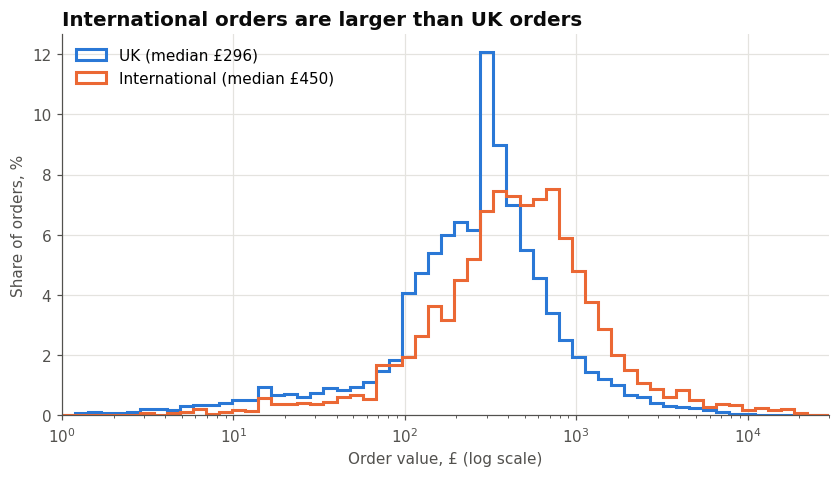

In [8]:
fig, ax = plt.subplots()
bins = np.logspace(0, 4.5, 60)
for data, c, name in [(uk, BLUE, "UK"), (intl, ORANGE, "International")]:
    ax.hist(data, bins=bins, weights=np.full(len(data), 100 / len(data)), histtype="step",
            color=c, linewidth=2, label=f"{name} (median £{np.median(data):,.0f})")
ax.set_xscale("log")
ax.set_xlim(1, 3e4)
ax.set_ylabel("Share of orders, %")
ax.set_xlabel("Order value, £ (log scale)")
ax.set_title("International orders are larger than UK orders")
ax.legend(loc="upper left")
fig.savefig(FIG / "uk_vs_international.png")
plt.show()

**3b. Repeat purchase rate.** Share of registered customers with 2+ orders, **Wilson** 95% CI per group and a **two-proportion Z-test**.
Each customer is assigned to the country of their first order.

In [9]:
cust = (orders.dropna(subset=["customer_id"]).sort_values("ts")
        .groupby("customer_id").agg(n_orders=("value", "size"), uk=("uk", "first")))
cust["repeat"] = cust.n_orders >= 2

def wilson(k, n):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

rows = []
for name, g in [("All", cust), ("UK", cust[cust.uk]), ("International", cust[~cust.uk])]:
    k, n = g.repeat.sum(), len(g)
    lo, hi = wilson(k, n)
    rows.append({"group": name, "customers": n, "repeaters": k, "rate": k / n, "95% CI low": lo, "95% CI high": hi})
repeat = pd.DataFrame(rows).set_index("group")

a, b = repeat.loc["UK"], repeat.loc["International"]
p_pool = (a.repeaters + b.repeaters) / (a.customers + b.customers)
z2 = (a.rate - b.rate) / np.sqrt(p_pool * (1 - p_pool) * (1 / a.customers + 1 / b.customers))
print(f"two-proportion Z-test UK vs international: z = {z2:.2f}, p = {2 * stats.norm.sf(abs(z2)):.3f}")
repeat

two-proportion Z-test UK vs international: z = 0.30, p = 0.765


,customers,repeaters,rate,95% CI low,95% CI high
group,,,,,
All,5878,4255,0.7239,0.7123,0.7352
UK,5349,3875,0.7244,0.7123,0.7362
International,529,380,0.7183,0.6785,0.7550


**Reading.** International orders are clearly larger: all three tests reject $H_0$, and a typical (geometric-mean) international order is ~1.8× a UK order.
But international customers are *not* more loyal: their repeat-purchase rate is the same as in the UK (the difference is not significant).
So the value of international customers comes from basket size, not from how often they return.

## 4. Time between orders: Gamma vs exponential

For each registered customer I take the gaps (in days) between consecutive orders; same-timestamp orders (gap = 0) are dropped.
An exponential model would mean customers reorder "memorylessly" at a constant rate. Gamma$(k, \theta)$ generalises it ($k = 1$ is exponential).

* **Method of moments**: $\tilde k = \bar x^2 / s^2$, $\tilde\theta = s^2/\bar x$.
* **MLE**: $\hat\theta = \bar x / \hat k$, where $\hat k$ solves $\ln k - \psi(k) = \ln\bar x - \overline{\ln x}$ (one-dimensional root, `scipy.optimize.brentq`).
  I cross-check it with a direct numerical maximisation of the log-likelihood (`scipy.optimize.minimize`).

In [10]:
reg = orders.dropna(subset=["customer_id"]).sort_values("ts")
gaps = (reg.groupby("customer_id").ts.diff().dt.total_seconds() / 86400).dropna()
gaps = gaps[gaps > 0].to_numpy()

def gamma_mom(g, axis=None):
    m, v = g.mean(axis=axis), g.var(axis=axis)
    return m**2 / v

def gamma_mle_shape(g):
    s = np.log(g.mean()) - np.log(g).mean()
    return optimize.brentq(lambda k: np.log(k) - special.digamma(k) - s, 1e-3, 1e3)

k_mom, k_mle = gamma_mom(gaps), gamma_mle_shape(gaps)

def neg_loglik(params):
    k, theta = np.exp(params)
    return -stats.gamma.logpdf(gaps, a=k, scale=theta).sum()

res = optimize.minimize(neg_loglik, x0=np.log([1.0, gaps.mean()]), method="Nelder-Mead")
k_num = np.exp(res.x[0])

ll_gamma = -neg_loglik(np.log([k_mle, gaps.mean() / k_mle]))
ll_exp = stats.expon.logpdf(gaps, scale=gaps.mean()).sum()
lr = 2 * (ll_gamma - ll_exp)

gamma_fit = pd.DataFrame({
    "k (shape)": [k_mom, k_mle, 1.0],
    "theta (scale), days": [gaps.mean() / k_mom, gaps.mean() / k_mle, gaps.mean()],
    "KS D": [stats.kstest(gaps, "gamma", args=(k_mom, 0, gaps.mean() / k_mom)).statistic,
             stats.kstest(gaps, "gamma", args=(k_mle, 0, gaps.mean() / k_mle)).statistic,
             stats.kstest(gaps, "expon", args=(0, gaps.mean())).statistic],
}, index=["Gamma, method of moments", "Gamma, MLE", "Exponential (MLE = MoM)"])
print(f"gaps: {len(gaps):,}, mean {gaps.mean():.1f} days, median {np.median(gaps):.1f} days")
print(f"MLE shape via brentq {k_mle:.4f}, via minimize {k_num:.4f}")
print(f"likelihood-ratio test Gamma vs exponential: LR = {lr:,.0f}, df = 1, p = {stats.chi2.sf(lr, 1):.1e}")
gamma_fit

gaps: 30,910, mean 52.0 days, median 25.0 days
MLE shape via brentq 0.3929, via minimize 0.3929
likelihood-ratio test Gamma vs exponential: LR = 27,485, df = 1, p = 0.0e+00


,k (shape),"theta (scale), days",KS D
"Gamma, method of moments",0.4691,110.8242,0.0787
"Gamma, MLE",0.3929,132.3074,0.1112
Exponential (MLE = MoM),1.0000,51.9893,0.1341


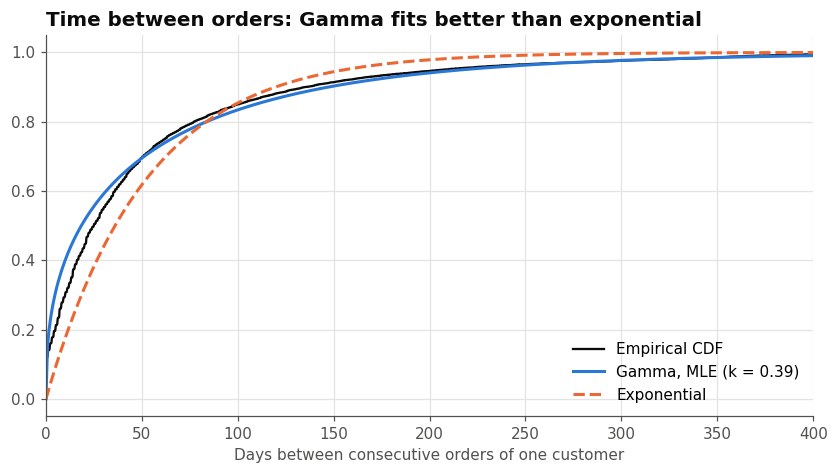

In [11]:
gs = np.sort(gaps)
t = np.linspace(0, 400, 500)
fig, ax = plt.subplots()
ax.step(gs, np.arange(1, len(gs) + 1) / len(gs), where="post", color=INK, linewidth=1.5, label="Empirical CDF")
ax.plot(t, stats.gamma.cdf(t, k_mle, scale=gaps.mean() / k_mle), color=BLUE, label=f"Gamma, MLE (k = {k_mle:.2f})")
ax.plot(t, stats.expon.cdf(t, scale=gaps.mean()), color=ORANGE, linestyle="--", label="Exponential")
ax.set_xlim(0, 400)
ax.set_xlabel("Days between consecutive orders of one customer")
ax.set_title("Time between orders: Gamma fits better than exponential")
ax.legend(loc="lower right")
fig.savefig(FIG / "gaps_ecdf.png")
plt.show()

**Reading.** $\hat k < 1$: the hazard of reordering *falls* with time since the last order. A customer is most likely to reorder soon after a purchase,
and the longer they have been away, the less likely they are to come back. For the business this argues for reaching out to lapsing customers early rather than waiting.
The exponential model is rejected by the likelihood-ratio test.

The two Gamma fits disagree: MLE has the higher likelihood, but MoM has the smaller KS distance. MLE is driven by the many very short gaps (same-week reorders)
and MoM by the overall mean and variance. Neither fits perfectly, which is a sign the Gamma family is only an approximation here (for example, a mixture of
"frequent" and "occasional" buyers). The next section checks which estimator is more reliable *when the model is true*.

## 5. Monte Carlo study: MLE vs method of moments for the Gamma shape

I simulate from Gamma($\hat k_{MLE}$, $\hat\theta_{MLE}$), the model fitted above, for several sample sizes, $R = 1000$ replicates each,
and compare the two shape estimators by bias, variance and MSE. Consistency means bias and MSE → 0 as $n$ grows.

In [12]:
k_true, theta_true = k_mle, gaps.mean() / k_mle
R = 1000
sizes = [30, 100, 300, 1000, 3000]
mc = []
for n in sizes:
    samples = rng.gamma(k_true, theta_true, size=(R, n))
    est = {"MoM": gamma_mom(samples, axis=1),
           "MLE": np.array([gamma_mle_shape(s) for s in samples])}
    for name, e in est.items():
        mc.append({"n": n, "estimator": name, "bias": e.mean() - k_true,
                   "variance": e.var(), "MSE": ((e - k_true) ** 2).mean()})
mc = pd.DataFrame(mc)
mc_wide = mc.pivot(index="n", columns="estimator", values=["bias", "variance", "MSE"])
mc_wide["MSE ratio MoM/MLE"] = mc_wide[("MSE", "MoM")] / mc_wide[("MSE", "MLE")]
print(f"true k = {k_true:.4f}")
mc_wide

true k = 0.3929


bias        variance           MSE        MSE ratio MoM/MLE
estimator    MLE    MoM      MLE    MoM    MLE    MoM                  
n                                                                      
30        0.0266 0.1038   0.0088 0.0343 0.0095 0.0450            4.7218
100       0.0085 0.0354   0.0023 0.0095 0.0023 0.0107            4.5898
300       0.0030 0.0146   0.0007 0.0032 0.0007 0.0034            5.2090
1000      0.0014 0.0046   0.0002 0.0011 0.0002 0.0011            5.7452
3000      0.0004 0.0021   0.0001 0.0004 0.0001 0.0004            5.5542

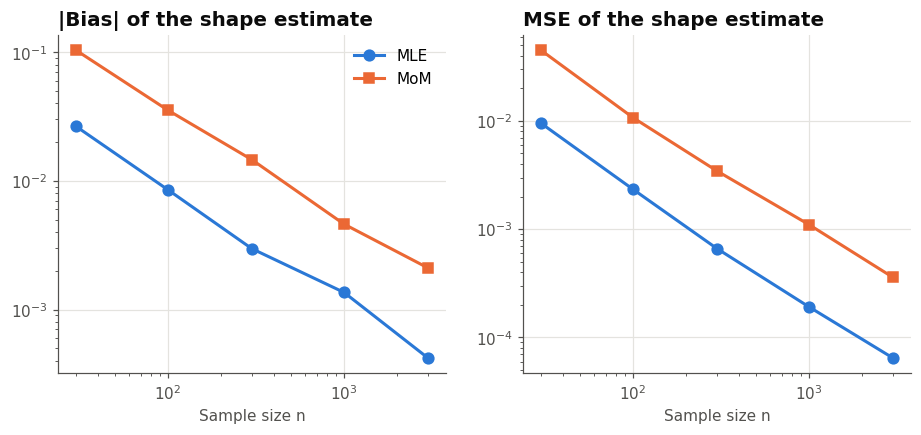

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for name, c, mk in [("MLE", BLUE, "o"), ("MoM", ORANGE, "s")]:
    d = mc[mc.estimator == name]
    axes[0].plot(d.n, d.bias.abs(), color=c, marker=mk, markersize=7, label=name)
    axes[1].plot(d.n, d.MSE, color=c, marker=mk, markersize=7, label=name)
for ax, title in zip(axes, ["|Bias| of the shape estimate", "MSE of the shape estimate"]):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Sample size n")
    ax.set_title(title)
axes[0].legend()
fig.savefig(FIG / "monte_carlo_mse.png")
plt.show()

**Reading.** Both estimators are consistent: bias and MSE shrink as $n$ grows (MSE roughly as $1/n$).
MLE has about 5× lower MSE than MoM at every sample size, so under a correctly specified Gamma model MLE is clearly the better estimator.
The gap between the two estimates on the real data (section 4) is therefore more a sign of model misspecification than of estimator noise.

## Summary

In [14]:
summary = pd.Series({
    "Orders analysed": f"{len(orders):,}",
    "Median order value (95% bootstrap CI)": f"£{np.median(x):,.0f} [£{ci.loc['median, bootstrap', 'low, £']:,.0f}; £{ci.loc['median, bootstrap', 'high, £']:,.0f}]",
    "Mean order value (95% CLT CI)": f"£{x.mean():,.0f} [£{ci.loc['mean, CLT', 'low, £']:,.0f}; £{ci.loc['mean, CLT', 'high, £']:,.0f}]",
    "Lognormal fit, KS D: MLE vs MoM": f"{lognorm_fit.loc['MLE', 'KS D']:.3f} vs {lognorm_fit.loc['Method of moments', 'KS D']:.3f}",
    "International vs UK, geometric-mean ratio": f"{np.exp(dlog):.2f}x [{np.exp(llo):.2f}x; {np.exp(lhi):.2f}x]",
    "Repeat-purchase rate (Wilson 95% CI)": f"{repeat.loc['All', 'rate']:.1%} [{repeat.loc['All', '95% CI low']:.1%}; {repeat.loc['All', '95% CI high']:.1%}]",
    "Time between orders, Gamma shape k (MLE)": f"{k_mle:.2f}",
    "MSE ratio MoM/MLE at n = 300": f"{mc_wide.loc[300, 'MSE ratio MoM/MLE'].item():.2f}",
}, name="result")
summary.to_frame()

,result
Orders analysed,"40,076"
Median order value (95% bootstrap CI),£302 [£301; £303]
Mean order value (95% CLT CI),£511 [£496; £525]
"Lognormal fit, KS D: MLE vs MoM",0.090 vs 0.225
"International vs UK, geometric-mean ratio",1.77x [1.69x; 1.84x]
Repeat-purchase rate (Wilson 95% CI),72.4% [71.2%; 73.5%]
"Time between orders, Gamma shape k (MLE)",0.39
MSE ratio MoM/MLE at n = 300,5.21
